lab 5. ant colony optimization, route optimization

AI Fundamentals and Applications

find short tour through 38 places in Djibouti with ACO. tune ρ and β, then compare with nearest neighbor and default GA from lab 4 by length and time

0. libraries and data

In [1]:
import math, random, time, urllib.request
from pathlib import Path
from itertools import product
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110

dataset dj38 from waterloo national TSP, downloads to data/ if not there

In [2]:
DATA = Path("data/dj38.tsp")
if not DATA.exists():
    DATA.parent.mkdir(exist_ok=True)
    urllib.request.urlretrieve("https://www.math.uwaterloo.ca/tsp/world/dj38.tsp", DATA)

1. load and plot locations

same as lab 4. rows after NODE_COORD_SECTION are `ID x y`. node 1 is the depot, route starts and ends there

In [3]:
coords = {}
reading = False
for line in DATA.read_text().splitlines():
    line = line.strip()
    if line == "NODE_COORD_SECTION":
        reading = True
    elif reading and line and line != "EOF":
        node_id, x, y = line.split()
        coords[int(node_id)] = (float(x), float(y))

NODES = sorted(coords)
DEPOT = 1
print("locations:", len(NODES))
print("node 1:", coords[DEPOT])

locations: 38
node 1: (11003.6111, 42102.5)


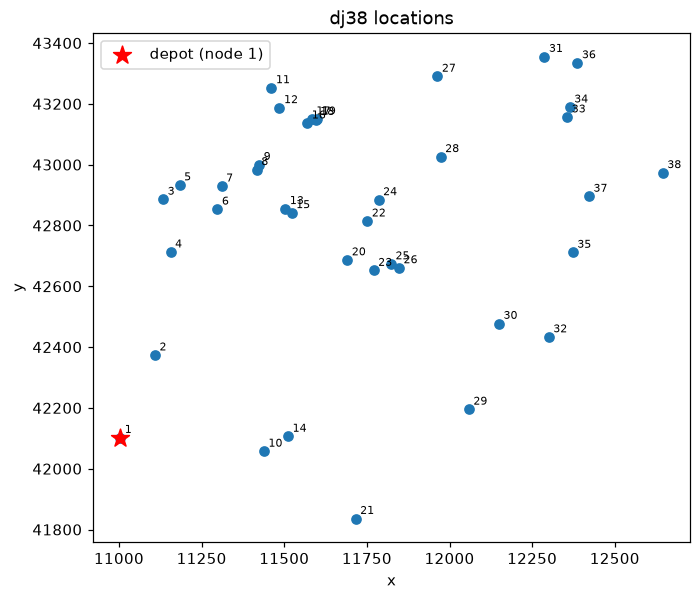

In [4]:
xs = [coords[n][0] for n in NODES]
ys = [coords[n][1] for n in NODES]

plt.figure(figsize=(7, 6))
plt.scatter(xs, ys, c="tab:blue")
for n in NODES:
    plt.annotate(str(n), coords[n], fontsize=7, xytext=(3, 3), textcoords="offset points")
plt.scatter(*coords[DEPOT], c="red", s=150, marker="*", label="depot (node 1)", zorder=3)
plt.title("dj38 locations"); plt.xlabel("x"); plt.ylabel("y"); plt.legend()
plt.show()

2. distance matrix and tour check

EUC_2D: straight line distance d, edge cost = int(d + 0.5).
tour = [1, ..., 1], every other node once. length = sum of all edges including way back to 1.
ACO divides by d^β, so also check that no two different nodes have cost 0

In [5]:
dist = {}
for a in NODES:
    for b in NODES:
        d = math.dist(coords[a], coords[b])
        dist[a, b] = int(d + 0.5)

def tour_length(tour):
    return sum(dist[tour[i], tour[i + 1]] for i in range(len(tour) - 1))

def check_tour(tour):
    ok = (tour[0] == DEPOT and tour[-1] == DEPOT
          and len(tour) == len(NODES) + 1
          and sorted(tour[1:-1]) == [n for n in NODES if n != DEPOT])
    print("valid" if ok else "NOT valid", "| length:", tour_length(tour))

print("dist(1, 2) =", dist[1, 2])
print("smallest edge between different nodes:", min(dist[a, b] for a in NODES for b in NODES if a != b))
check_tour([1] + list(range(2, 39)) + [1])

dist(1, 2) = 291
smallest edge between different nodes: 5
valid | length: 17098


3. baselines from lab 4

nearest neighbor: start at 1, always go to closest unvisited node. tie -> smaller ID. then go back to 1

In [6]:
def nearest_neighbor():
    tour = [DEPOT]
    unvisited = [n for n in NODES if n != DEPOT]
    while unvisited:
        here = tour[-1]
        nxt = min(unvisited, key=lambda n: (dist[here, n], n))
        tour.append(nxt)
        unvisited.remove(nxt)
    return tour + [DEPOT]

nn_tour = nearest_neighbor()
print(nn_tour)
check_tour(nn_tour)

[1, 2, 4, 3, 5, 7, 6, 8, 9, 13, 15, 20, 23, 25, 26, 22, 24, 28, 27, 31, 36, 34, 33, 37, 35, 32, 30, 29, 21, 14, 10, 16, 17, 18, 19, 12, 11, 38, 1]
valid | length: 9745


default GA, same code as lab 4:
- chromosome = order of 37 nodes without depot, random start
- tournament selection k=3, ordered crossover with p=0.90, swap mutation 0.25, 2 elites
- population 80, 120 generations -> 80 + 120*80 = 9680 tours per run

In [7]:
def fitness(chrom):
    return tour_length([DEPOT] + chrom + [DEPOT])

def tournament(pop, scores, k, rng):
    picked = rng.sample(range(len(pop)), k)
    best = min(picked, key=lambda i: scores[i])
    return pop[best]

def ordered_crossover(p1, p2, rng):
    a, b = sorted(rng.sample(range(len(p1)), 2))
    child = [None] * len(p1)
    child[a:b + 1] = p1[a:b + 1]
    rest = [g for g in p2 if g not in child[a:b + 1]]
    for i in range(len(child)):
        if child[i] is None:
            child[i] = rest.pop(0)
    return child

def swap_mutation(chrom, rate, rng):
    chrom = chrom[:]
    if rng.random() < rate:
        i, j = rng.sample(range(len(chrom)), 2)
        chrom[i], chrom[j] = chrom[j], chrom[i]
    return chrom

def run_ga(seed, pop_size=80, generations=120, tour_size=3,
           cx_prob=0.90, mut_rate=0.25, elites=2):
    rng = random.Random(seed)
    cities = [n for n in NODES if n != DEPOT]

    pop = [rng.sample(cities, len(cities)) for _ in range(pop_size)]
    scores = [fitness(c) for c in pop]
    evals = pop_size
    best_so_far = [min(scores)]

    for _ in range(generations):
        order = sorted(range(pop_size), key=lambda i: scores[i])
        new_pop = [pop[i][:] for i in order[:elites]]
        while len(new_pop) < pop_size:
            p1 = tournament(pop, scores, tour_size, rng)
            p2 = tournament(pop, scores, tour_size, rng)
            child = ordered_crossover(p1, p2, rng) if rng.random() < cx_prob else p1[:]
            new_pop.append(swap_mutation(child, mut_rate, rng))
        pop = new_pop
        scores = [fitness(c) for c in pop]
        evals += pop_size
        best_so_far.append(min(best_so_far[-1], min(scores)))

    best = pop[min(range(pop_size), key=lambda i: scores[i])]
    return [DEPOT] + best + [DEPOT], best_so_far, evals

tour, _, evals = run_ga(seed=0)
print("default GA | evaluations:", evals, end=" | ")
check_tour(tour)

default GA | evaluations:

 9680 | valid | length: 11762


4. ant colony optimization

idea: ants walk through the graph and leave pheromone on edges. short tours leave more pheromone, so next ants choose those edges more often. good edges get stronger, bad ones slowly disappear

- every edge has trail τ, at start τ = 6. graph is symmetric so (a, b) and (b, a) share one value
- ant starts at node 1. from node i it picks next unvisited j with probability

  p(j) = (τ_ij / d_ij^β) / Σ (τ_ik / d_ik^β) over all unvisited k

  so edge is good if it has a lot of pheromone and is short. β says how much we care about distance (β big -> almost greedy like NN)
- after visiting all, ant goes back to 1, tour is scored, best tour so far is kept
- after all ants of a round finish:
  - evaporation: τ = (1 - ρ) · τ on every edge. ρ big -> colony forgets old routes fast
  - deposit: each ant adds Q / L to every edge it used (with return to depot), Q = 36, L = its tour length

40 ants × 242 rounds = 9680 tours per run, same budget as GA

In [8]:
def build_tour(tau, beta, rng):
    tour = [DEPOT]
    unvisited = [n for n in NODES if n != DEPOT]
    while unvisited:
        here = tour[-1]
        weights = [tau[here, n] / dist[here, n] ** beta for n in unvisited]
        nxt = rng.choices(unvisited, weights)[0]
        tour.append(nxt)
        unvisited.remove(nxt)
    return tour + [DEPOT]

def run_aco(seed, n_ants=40, rounds=242, rho=0.50, beta=1, tau0=6, q=36):
    rng = random.Random(seed)
    tau = {(a, b): tau0 for a in NODES for b in NODES if a != b}
    best_tour, best_len = None, float("inf")
    best_so_far = []
    evals = 0

    for _ in range(rounds):
        ants = []
        for _ in range(n_ants):
            tour = build_tour(tau, beta, rng)
            length = tour_length(tour)
            evals += 1
            ants.append((tour, length))
            if length < best_len:
                best_tour, best_len = tour, length

        for edge in tau:
            tau[edge] *= 1 - rho
        for tour, length in ants:
            for a, b in zip(tour, tour[1:]):
                tau[a, b] += q / length
                tau[b, a] += q / length

        best_so_far.append(best_len)

    return best_tour, best_so_far, evals

quick test of default ACO (ρ = 0.50, β = 1) with seed 0

In [9]:
tour, _, evals = run_aco(seed=0)
print("default ACO | evaluations:", evals, end=" | ")
check_tour(tour)

default ACO | evaluations: 9680 | valid | length: 6791


5. tuning ACO

grid search over all 9 pairs: ρ 0.10/0.30/0.50 x β 1/2/3. every pair runs with seeds 1, 2, 3 (40 ants, 242 rounds, τ0 = 6, Q = 36).
pick lowest mean length. tie -> lower ρ, then smaller β

In [10]:
rows = []
for rho, beta in product([0.10, 0.30, 0.50], [1, 2, 3]):
    lengths = []
    for seed in [1, 2, 3]:
        tour, _, _ = run_aco(seed, rho=rho, beta=beta)
        lengths.append(tour_length(tour))
    rows.append({"rho": rho, "beta": beta,
                 "seed 1": lengths[0], "seed 2": lengths[1], "seed 3": lengths[2],
                 "mean": round(np.mean(lengths), 1)})

grid = pd.DataFrame(rows).sort_values(["mean", "rho", "beta"]).reset_index(drop=True)
BEST_RHO = grid.loc[0, "rho"]
BEST_BETA = int(grid.loc[0, "beta"])
print(f"selected: rho = {BEST_RHO}, beta = {BEST_BETA}")
grid

selected: rho = 0.1, beta = 2


,rho,beta,seed 1,seed 2,seed 3,mean
0,0.1,2,6708,6659,6694,6687.0
1,0.1,3,6661,6704,6696,6687.0
2,0.3,2,6694,6659,6739,6697.3
3,0.3,3,6751,6704,6710,6721.7
4,0.3,1,6691,6863,6696,6750.0
5,0.5,3,6778,6704,6780,6754.0
6,0.5,1,6727,6831,6719,6759.0
7,0.5,2,6809,6704,6774,6762.3
8,0.1,1,6659,6774,6878,6770.3


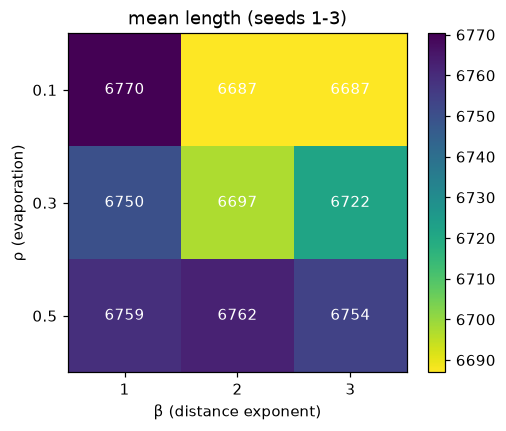

In [11]:
pivot = grid.pivot(index="rho", columns="beta", values="mean")
plt.figure(figsize=(5, 4))
plt.imshow(pivot, cmap="viridis_r")
plt.xticks(range(3), pivot.columns); plt.yticks(range(3), pivot.index)
for i in range(3):
    for j in range(3):
        plt.text(j, i, f"{pivot.iloc[i, j]:.0f}", ha="center", va="center", color="white")
plt.xlabel("β (distance exponent)"); plt.ylabel("ρ (evaporation)"); plt.title("mean length (seeds 1-3)")
plt.colorbar(); plt.show()

6. final comparison

default GA, default ACO and tuned ACO with seeds 4, 5, 6. each run scores 9680 tours. time with perf_counter, dist matrix is already built. NN runs once

In [12]:
start = time.perf_counter()
nn_tour = nearest_neighbor()
nn_time = time.perf_counter() - start
nn_len = tour_length(nn_tour)

methods = {
    "Default GA": lambda seed: run_ga(seed),
    "Default ACO": lambda seed: run_aco(seed),
    "Tuned ACO": lambda seed: run_aco(seed, rho=BEST_RHO, beta=BEST_BETA),
}

final = {}
for name, run in methods.items():
    final[name] = []
    for seed in [4, 5, 6]:
        start = time.perf_counter()
        tour, hist, evals = run(seed)
        sec = time.perf_counter() - start
        final[name].append({"seed": seed, "tour": tour, "length": tour_length(tour),
                            "time": sec, "hist": hist, "evals": evals})
        print(f"{name}, seed {seed}, {evals} tours:", end=" ")
        check_tour(tour)

Default GA, seed 4, 9680 tours: valid | length: 10906


Default GA, seed 5, 9680 tours: valid | length: 9112
Default GA, seed 6, 9680 tours: valid | length: 10513


Default ACO, seed 4, 9680 tours: valid | length: 6663


Default ACO, seed 5, 9680 tours: valid | length: 6663


Default ACO, seed 6, 9680 tours: valid | length: 6778


Tuned ACO, seed 4, 9680 tours: valid | length: 6694


Tuned ACO, seed 5, 9680 tours: valid | length: 6663


Tuned ACO, seed 6, 9680 tours: valid | length: 6659


In [13]:
settings = {
    "Nearest Neighbor": "depot 1",
    "Default GA": "random start",
    "Default ACO": "ρ = 0.50, β = 1",
    "Tuned ACO": f"ρ = {BEST_RHO:.2f}, β = {BEST_BETA}",
}
table = [{"Method": "Nearest Neighbor", "Settings": settings["Nearest Neighbor"],
          "Best length": nn_len, "Mean length": nn_len, "Mean time (s)": round(nn_time, 5)}]
for name, runs in final.items():
    lengths = [r["length"] for r in runs]
    table.append({"Method": name, "Settings": settings[name],
                  "Best length": min(lengths), "Mean length": round(np.mean(lengths), 1),
                  "Mean time (s)": round(np.mean([r["time"] for r in runs]), 3)})
table = pd.DataFrame(table)
table

,Method,Settings,Best length,Mean length,Mean time (s)
0,Nearest Neighbor,depot 1,9745,9745.0,0.00009
1,Default GA,random start,9112,10177.0,0.10200
2,Default ACO,"ρ = 0.50, β = 1",6663,6701.3,0.95700
3,Tuned ACO,"ρ = 0.10, β = 2",6659,6672.0,1.15400


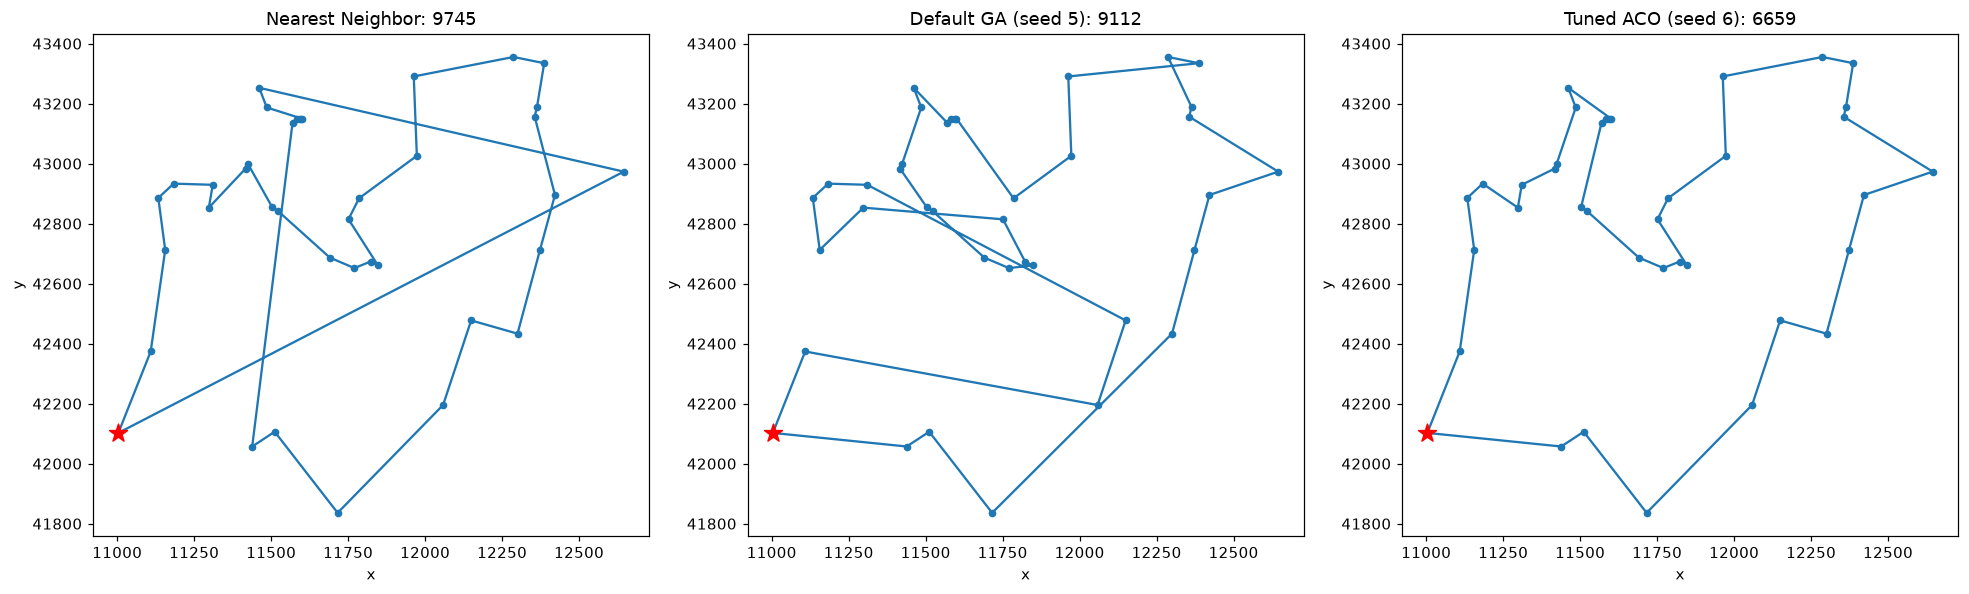

In [14]:
best_ga = min(final["Default GA"], key=lambda r: r["length"])
best_aco = min(final["Tuned ACO"], key=lambda r: r["length"])

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, tour, title in [(axes[0], nn_tour, f"Nearest Neighbor: {nn_len}"),
                        (axes[1], best_ga["tour"], f"Default GA (seed {best_ga['seed']}): {best_ga['length']}"),
                        (axes[2], best_aco["tour"], f"Tuned ACO (seed {best_aco['seed']}): {best_aco['length']}")]:
    ax.plot([coords[n][0] for n in tour], [coords[n][1] for n in tour], "-o", ms=4)
    ax.scatter(*coords[DEPOT], c="red", s=150, marker="*", zorder=3)
    ax.set_title(title); ax.set_xlabel("x"); ax.set_ylabel("y")
plt.tight_layout(); plt.show()

convergence for seed 4. x axis = complete tours scored: GA scores 80 per generation (gen 0 included), ACO scores 40 per round

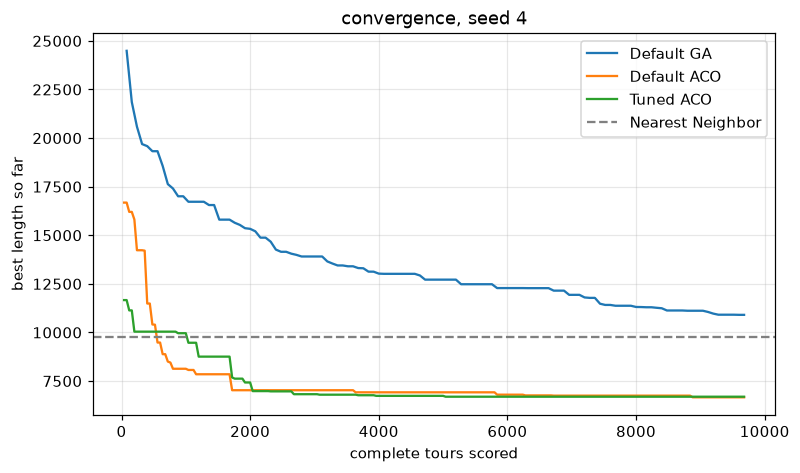

In [15]:
plt.figure(figsize=(8, 4.5))
for name, step in [("Default GA", 80), ("Default ACO", 40), ("Tuned ACO", 40)]:
    run4 = [r for r in final[name] if r["seed"] == 4][0]
    x = [step * (i + 1) for i in range(len(run4["hist"]))]
    plt.plot(x, run4["hist"], label=name)
plt.axhline(nn_len, color="gray", ls="--", label="Nearest Neighbor")
plt.xlabel("complete tours scored"); plt.ylabel("best length so far"); plt.title("convergence, seed 4")
plt.legend(); plt.grid(alpha=0.3); plt.show()

conclusion

shortest tour: tuned ACO (ρ = 0.10, β = 2), 6659 on seed 6. default ACO best 6663, default GA best 9112, NN 9745. known optimum of dj38 is 6656, so tuned ACO is only 3 units away

ACO is much better than GA here with the same budget of 9680 tours. GA starts from random permutations and in 120 generations doesnt even beat NN on average (mean 10177). ACO uses distance in every step (1/d^β), so even first ants build NN-like tours, then pheromone pushes the colony to the best edges. in convergence chart both ACO lines are below NN after the first round, GA stays above

tuning: grid picked ρ = 0.10, β = 2 with mean 6687.0. it was an exact tie with ρ = 0.10, β = 3 (also 6687.0), rule says smaller β wins. low ρ = slow evaporation, colony keeps good edges longer. β = 2 makes short edges more attractive than β = 1. on seeds 4-6 mean went from 6701.3 (default) to 6672.0, about 29 shorter, and all 3 tuned runs are within 38 of optimum. difference is small bc default ACO is already close to optimum

time: NN is less than 1 ms, GA ~0.1 s, ACO ~1 s per run (default 0.96 s, tuned 1.15 s). ACO is ~10x slower than GA bc every step computes weights for all unvisited nodes and does weighted random choice, GA only copies and swaps lists. β = 2 is a bit slower than β = 1 bc of the power. but for this extra second ACO gives ~30% shorter tours than GA